# Step 5 — Model Probabilistik: Okapi BM25

**Tujuan praktikum**
1. Mahasiswa memahami ide model probabilistik dan fungsi pemeringkatan BM25.
2. Mahasiswa mampu mengimplementasikan BM25 dengan parameter $k_1$ dan $b$.
3. Mahasiswa mampu menganalisis pengaruh saturasi TF dan normalisasi panjang dokumen.

**Rumus BM25**

$$\text{score}(q,d) = \sum_{t \in q} \text{IDF}(t) \cdot \frac{tf_{t,d}\,(k_1+1)}{tf_{t,d} + k_1\left(1 - b + b\,\frac{|d|}{avgdl}\right)}$$

$$\text{IDF}(t) = \ln\left(1 + \frac{N - df_t + 0.5}{df_t + 0.5}\right)$$

In [1]:
# Jalankan sekali jika pustaka belum terpasang:
# !pip install pandas numpy matplotlib Sastrawi
import pandas as pd
pd.set_option("display.max_colwidth", 120)

In [2]:
import math
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
from stki_utils import corpus_texts, preprocess, build_inverted_index, load_corpus, TfidfModel

judul = dict(zip(load_corpus().doc_id, load_corpus().judul))
docs = {d: preprocess(t) for d, t in corpus_texts().items()}
index = build_inverted_index(docs)
N = len(docs)
doc_len = {d: len(t) for d, t in docs.items()}
avgdl = sum(doc_len.values()) / N
print(f"N = {N}, avgdl = {avgdl:.2f}, dokumen terpendek = {min(doc_len.values())}, terpanjang = {max(doc_len.values())}")

N = 30, avgdl = 28.77, dokumen terpendek = 25, terpanjang = 38


## Langkah 1 — Implementasi BM25

In [3]:
def bm25_idf(term):
    df = len(index.get(term, {}))
    return math.log(1 + (N - df + 0.5) / (df + 0.5))

def bm25_score(q_tokens, doc_id, k1=1.5, b=0.75):
    skor = 0.0
    for t in q_tokens:
        tf = index.get(t, {}).get(doc_id, 0)
        if tf:
            norm = k1 * (1 - b + b * doc_len[doc_id] / avgdl)
            skor += bm25_idf(t) * tf * (k1 + 1) / (tf + norm)
    return skor

def bm25_search(query, k=5, k1=1.5, b=0.75):
    q = preprocess(query)
    kandidat = {d for t in q for d in index.get(t, {})}
    skor = {d: bm25_score(q, d, k1, b) for d in kandidat}
    return sorted(skor.items(), key=lambda x: (-x[1], x[0]))[:k]

hasil = bm25_search("harga hasil panen petani")
pd.DataFrame([(d, judul[d], round(s, 4)) for d, s in hasil], columns=["doc_id", "judul", "BM25"])

,doc_id,judul,BM25
0,D12,Harga Gabah Saat Panen Raya,9.5757
1,D07,Budidaya Padi Sawah,6.2919
2,D23,Ekspor Kopi Nusantara,3.6440
3,D20,Memahami Inflasi,3.1788
4,D10,Pertanian Cerdas Berbasis IoT,2.3401


In [4]:
from stki_utils import BM25Model

model = BM25Model(docs)
print("Sama dengan stki_utils.BM25Model:",
      [d for d, _ in model.search(preprocess("harga hasil panen petani"), 5)] == [d for d, _ in hasil])

Sama dengan stki_utils.BM25Model: True


## Langkah 2 — Saturasi term frequency ($k_1$)
Pada TF-IDF, kontribusi TF terus naik. Pada BM25, kontribusi TF mendekati batas atas $k_1 + 1$, sehingga dokumen yang mengulang-ulang satu kata tidak mendapat skor berlebihan.

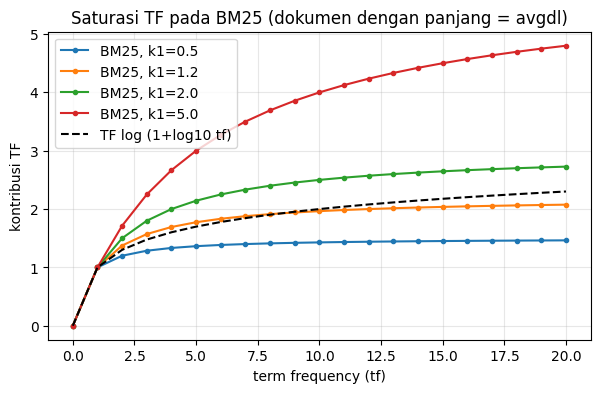

In [5]:
tf = list(range(0, 21))
plt.figure(figsize=(7, 4))
for k1 in [0.5, 1.2, 2.0, 5.0]:
    plt.plot(tf, [x * (k1 + 1) / (x + k1) for x in tf], marker=".", label=f"BM25, k1={k1}")
plt.plot(tf, [1 + math.log10(x) if x else 0 for x in tf], "k--", label="TF log (1+log10 tf)")
plt.xlabel("term frequency (tf)"); plt.ylabel("kontribusi TF")
plt.title("Saturasi TF pada BM25 (dokumen dengan panjang = avgdl)")
plt.legend(); plt.grid(alpha=.3); plt.show()

## Langkah 3 — Normalisasi panjang dokumen ($b$)
$b = 0$ berarti panjang dokumen diabaikan; $b = 1$ berarti normalisasi penuh.

In [6]:
query = "keamanan data pribadi di internet"
tabel = {}
for b in [0.0, 0.5, 0.75, 1.0]:
    tabel[f"b={b}"] = [f"{d} ({s:.2f})" for d, s in bm25_search(query, k=5, b=b)]
pd.DataFrame(tabel, index=range(1, 6))

,b=0.0,b=0.5,b=0.75,b=1.0
1,D15 (6.77),D15 (6.76),D15 (6.75),D15 (6.74)
2,D06 (3.74),D06 (3.90),D06 (3.98),D06 (4.06)
3,D10 (3.74),D16 (3.85),D16 (3.91),D16 (3.97)
4,D16 (3.74),D10 (3.70),D10 (3.67),D10 (3.65)
5,D25 (3.12),D25 (3.13),D25 (3.14),D25 (3.15)


## Langkah 4 — Membandingkan TF-IDF dan BM25

In [7]:
tfidf = TfidfModel(docs)
for q in ["teknologi pertanian modern", "pemasaran digital UMKM", "keamanan data pribadi di internet"]:
    a = [d for d, _ in tfidf.search(preprocess(q), 5)]
    b = [d for d, _ in model.search(preprocess(q), 5)]
    print(f"{q}\n  TF-IDF: {a}\n  BM25  : {b}\n")

teknologi pertanian modern
  TF-IDF: ['D10', 'D06', 'D27', 'D12', 'D08']
  BM25  : ['D10', 'D12', 'D06', 'D27', 'D08']

pemasaran digital UMKM
  TF-IDF: ['D19', 'D22', 'D24', 'D27', 'D21']
  BM25  : ['D19', 'D22', 'D21', 'D27', 'D29']

keamanan data pribadi di internet
  TF-IDF: ['D15', 'D06', 'D16', 'D10', 'D25']
  BM25  : ['D15', 'D06', 'D16', 'D10', 'D25']



## Tugas Step 5
1. Lakukan *grid search* $k_1 \in \{0.5, 1.0, 1.2, 1.5, 2.0\}$ dan $b \in \{0, 0.25, 0.5, 0.75, 1.0\}$. Simpan kombinasi yang menghasilkan MAP terbaik (gunakan fungsi evaluasi dari Step 6).
2. Buat satu dokumen buatan yang sangat panjang dan mengulang kata `tani` 20 kali. Tambahkan ke korpus, lalu bandingkan peringkatnya pada TF-IDF dan BM25 untuk query `tani`. Jelaskan.

## Jawaban Tugas Step 5
1. Lakukan *grid search* $k_1 \in \{0.5, 1.0, 1.2, 1.5, 2.0\}$ dan $b \in \{0, 0.25, 0.5, 0.75, 1.0\}$. Simpan kombinasi yang menghasilkan MAP terbaik (gunakan fungsi evaluasi dari Step 6).


In [8]:
from stki_utils import load_queries, load_qrels, evaluate

queries, qrels = load_queries(), load_qrels()

hasil = []
for k1 in [0.5, 1.0, 1.2, 1.5, 2.0]:
    for b in [0, 0.25, 0.5, 0.75, 1.0]:
        run = {q: [d for d, _ in bm25_search(t, k=10, k1=k1, b=b)] for q, t in queries.items()}
        hasil.append((k1, b, evaluate(run, qrels, k=5).loc["Rata-rata", "AP"]))

df = pd.DataFrame(hasil, columns=["k1", "b", "MAP"]).sort_values("MAP", ascending=False)
print(df.head())
print("\nTerbaik:", df.iloc[0].to_dict())

     k1     b     MAP
5   1.0  0.00  0.7791
15  1.5  0.00  0.7791
20  2.0  0.00  0.7791
10  1.2  0.00  0.7791
6   1.0  0.25  0.7756

Terbaik: {'k1': 1.0, 'b': 0.0, 'MAP': 0.7791}


2. Buat satu dokumen buatan yang sangat panjang dan mengulang kata `tani` 20 kali. Tambahkan ke korpus, lalu bandingkan peringkatnya pada TF-IDF dan BM25 untuk query `tani`. Jelaskan.

In [9]:
# penambahan dokumen dengan 20 kata tani
teks_d31 = """Kehidupan manusia merupakan sebuah perjalanan panjang yang dipenuhi dengan berbagai pengalaman, tantangan, harapan, serta kesempatan untuk terus berkembang. Setiap orang memiliki cerita yang berbeda, mulai dari masa kecil yang penuh dengan rasa ingin tahu, masa remaja yang dipenuhi dengan pencarian jati diri, hingga masa dewasa ketika seseorang mulai memahami arti tanggung jawab dan pentingnya mengambil keputusan secara bijaksana. Dalam perjalanan tersebut, manusia belajar bahwa keberhasilan tidak selalu datang dengan mudah, melainkan membutuhkan kesabaran, ketekunan, keberanian, dan kemauan untuk terus memperbaiki diri meskipun menghadapi berbagai kesulitan. Di sebuah desa yang terletak jauh dari hiruk-pikuk perkotaan, kehidupan berjalan dengan ritme yang relatif tenang. Matahari terbit perlahan dari balik perbukitan, menerangi rumah-rumah sederhana, jalanan kecil, serta hamparan pepohonan yang tumbuh di sepanjang sungai. Udara pagi terasa sejuk, sementara suara burung terdengar bersahutan dari dahan-dahan pohon yang mulai dipenuhi cahaya keemasan. Penduduk desa biasanya memulai aktivitas sejak pagi hari, mempersiapkan kebutuhan keluarga, membersihkan halaman rumah, dan menjalankan pekerjaan masing-masing. Di antara mereka, terdapat seorang tani yang selalu memulai harinya sebelum matahari benar-benar muncul. Ia percaya bahwa kedisiplinan merupakan salah satu kunci untuk menjalani kehidupan dengan lebih baik. Tidak jauh dari rumahnya, terdapat seorang tani yang mengelola sebidang tanah dengan penuh perhatian. Ia memahami bahwa alam memiliki siklusnya sendiri dan bahwa manusia tidak dapat memaksakan segala sesuatu berjalan sesuai keinginannya. Ketika musim hujan datang, ia harus memastikan bahwa air dapat mengalir dengan baik agar tidak merusak tanaman. Sebaliknya, ketika musim kemarau tiba, ia perlu memikirkan cara untuk mempertahankan kelembapan tanah agar tumbuhan tetap dapat bertahan hidup. Pengetahuan seperti ini tidak selalu diperoleh melalui pendidikan formal, tetapi juga melalui pengalaman bertahun-tahun, pengamatan terhadap lingkungan, serta percakapan dengan orang-orang yang memiliki pengalaman serupa. Di sisi lain desa, seorang tani muda mulai memperkenalkan berbagai pendekatan baru dalam mengelola sumber daya alam. Ia mempelajari teknologi sederhana yang dapat membantu mengukur kelembapan tanah, memperkirakan kebutuhan air, dan mencatat perubahan cuaca. Menurutnya, perkembangan teknologi tidak seharusnya membuat manusia menjauh dari alam. Sebaliknya, teknologi dapat menjadi alat yang membantu manusia memahami lingkungan secara lebih mendalam. Ia juga menyadari bahwa tidak semua orang memiliki kesempatan yang sama untuk mempelajari teknologi tersebut, sehingga ia berusaha menjelaskan manfaatnya dengan bahasa yang mudah dipahami oleh masyarakat setempat. Pada suatu sore, sekelompok penduduk berkumpul di balai desa untuk membicarakan masa depan lingkungan mereka. Seorang tani senior menyampaikan pendapat bahwa perubahan perlu dilakukan secara bertahap agar masyarakat tidak merasa terbebani. Ia menjelaskan bahwa kebiasaan yang telah diwariskan selama puluhan tahun tidak dapat diubah hanya melalui satu pertemuan. Diperlukan komunikasi yang baik, contoh nyata, serta kesempatan bagi setiap orang untuk mencoba pendekatan baru sebelum memutuskan apakah pendekatan tersebut benar-benar bermanfaat. Pendapat itu mendapat dukungan dari banyak peserta karena mereka memahami bahwa perubahan yang bertahan lama biasanya dibangun melalui kerja sama, bukan paksaan. Dalam pertemuan tersebut, seorang tani lainnya mengusulkan agar desa mulai membangun tempat penyimpanan hasil panen yang lebih terorganisasi. Ia berpendapat bahwa hasil kerja keras masyarakat harus dijaga dengan baik supaya tidak mengalami kerusakan sebelum dimanfaatkan. Selain itu, ia mengusulkan pembentukan kelompok yang bertugas memantau kondisi lingkungan dan menyampaikan informasi mengenai cuaca kepada penduduk. Usulan tersebut kemudian dibahas bersama untuk menentukan kebutuhan, biaya, serta pembagian tanggung jawab. Meskipun tidak semua orang langsung menyetujui gagasan itu, diskusi berlangsung dengan terbuka dan penuh rasa hormat. Seorang tani perempuan yang selama ini aktif dalam kegiatan masyarakat kemudian berbicara mengenai pentingnya pendidikan bagi generasi muda. Ia mengatakan bahwa anak-anak perlu memperoleh kesempatan untuk mengenal berbagai bidang pengetahuan tanpa harus meninggalkan nilai-nilai yang telah dijunjung tinggi oleh keluarga dan masyarakat. Menurutnya, pendidikan tidak hanya berkaitan dengan kemampuan membaca, menulis, atau berhitung, tetapi juga mencakup keterampilan berkomunikasi, berpikir kritis, bekerja sama, dan menyelesaikan masalah. Ia berharap anak-anak di desa tersebut dapat tumbuh menjadi individu yang mampu beradaptasi dengan perubahan zaman sekaligus tetap menghargai lingkungan tempat mereka dibesarkan. Pada kesempatan berikutnya, seorang tani yang baru kembali dari kota membagikan pengalamannya selama mengikuti pelatihan kewirausahaan. Ia menceritakan bagaimana sebuah produk sederhana dapat memiliki nilai ekonomi yang lebih tinggi apabila dikemas dengan baik, dipasarkan kepada konsumen yang tepat, dan didukung oleh pelayanan yang memuaskan. Pengalaman itu membuat masyarakat mulai menyadari bahwa peningkatan kesejahteraan tidak hanya bergantung pada jumlah barang yang dihasilkan, tetapi juga pada kemampuan mengelola kualitas, distribusi, dan hubungan dengan pelanggan. Mereka kemudian mempertimbangkan berbagai kemungkinan untuk mengembangkan usaha bersama yang dapat memberikan manfaat bagi banyak keluarga. Di tengah pembicaraan yang semakin berkembang, seorang tani tua mengingatkan bahwa keberhasilan ekonomi tidak boleh menjadi satu-satunya ukuran kemajuan sebuah masyarakat. Ia pernah menyaksikan bagaimana suatu wilayah mengalami perkembangan pesat, tetapi pada saat yang sama kehilangan sebagian ruang terbuka hijau, sumber air bersih, dan hubungan sosial antarpenghuninya. Menurutnya, pembangunan yang baik harus mempertimbangkan kebutuhan manusia sekaligus menjaga keseimbangan alam. Ia berharap desa mereka tidak mengulangi kesalahan yang sama dan dapat menemukan cara untuk berkembang tanpa merusak sumber daya yang akan dibutuhkan oleh generasi mendatang. Beberapa hari setelah pertemuan tersebut, sekelompok pemuda mulai menyusun rencana kegiatan bersama. Seorang tani muda ditunjuk sebagai salah satu koordinator karena dianggap memiliki pengalaman dalam mengorganisasi pekerjaan. Ia membagi kegiatan menjadi beberapa tahap, mulai dari pengumpulan informasi, penyusunan kebutuhan, pelaksanaan percobaan, hingga evaluasi hasil. Setiap anggota kelompok diberikan tanggung jawab yang sesuai dengan kemampuan masing-masing. Ada yang bertugas mengumpulkan data, ada yang menyiapkan peralatan, dan ada pula yang mendokumentasikan perkembangan kegiatan agar dapat dipelajari kembali pada masa mendatang. Dalam proses pelaksanaannya, seorang tani menyadari bahwa rencana yang terlihat sempurna di atas kertas belum tentu berjalan sesuai harapan ketika diterapkan secara langsung. Beberapa peralatan ternyata tidak bekerja dengan baik, sementara sebagian informasi yang dikumpulkan sebelumnya perlu diperiksa kembali. Namun, kelompok tersebut tidak menganggap hambatan itu sebagai alasan untuk berhenti. Mereka mengadakan diskusi, mencari penyebab masalah, dan mencoba beberapa alternatif penyelesaian. Pengalaman tersebut mengajarkan mereka bahwa proses belajar sering kali melibatkan kesalahan, dan bahwa kesalahan dapat menjadi sumber pengetahuan apabila ditanggapi dengan sikap terbuka. Sementara itu, seorang tani yang bertugas mengumpulkan informasi mulai menggunakan komputer untuk menyimpan catatan kegiatan. Ia membuat tabel sederhana yang berisi tanggal, kondisi lingkungan, kebutuhan peralatan, serta hasil pengamatan. Dengan pencatatan yang lebih teratur, kelompok dapat membandingkan keadaan dari waktu ke waktu dan mengidentifikasi perubahan yang sebelumnya sulit terlihat. Mereka juga belajar bahwa data tidak akan memberikan manfaat maksimal apabila dikumpulkan tanpa tujuan yang jelas. Oleh sebab itu, setiap informasi perlu diperiksa, dikelompokkan, dan dianalisis sebelum digunakan untuk mengambil keputusan. Pada bulan berikutnya, seorang tani mengusulkan agar hasil kegiatan dibagikan kepada masyarakat melalui papan informasi desa. Ia berpendapat bahwa keterbukaan informasi dapat membantu penduduk memahami apa yang sedang dilakukan dan bagaimana mereka dapat berpartisipasi. Kelompok kemudian menyiapkan ringkasan kegiatan dengan menggunakan bahasa sederhana, gambar pendukung, dan penjelasan mengenai hasil yang telah dicapai. Mereka juga mencantumkan beberapa hal yang masih perlu diperbaiki agar masyarakat mengetahui bahwa kegiatan tersebut belum sepenuhnya selesai. Pendekatan ini mendapatkan respons positif karena penduduk merasa dilibatkan dalam proses pengambilan keputusan. Dalam sebuah diskusi lanjutan, seorang tani mengangkat persoalan mengenai pengelolaan sampah rumah tangga. Ia menjelaskan bahwa sampah yang dibuang sembarangan dapat menyumbat saluran air, mencemari sungai, dan menimbulkan gangguan kesehatan. Ia mengusulkan agar masyarakat mulai memilah sampah berdasarkan jenisnya serta memanfaatkan kembali bahan yang masih dapat digunakan. Beberapa penduduk kemudian menawarkan gagasan untuk mengadakan kegiatan kebersihan secara rutin. Mereka sepakat bahwa menjaga lingkungan bukan hanya tanggung jawab pemerintah atau kelompok tertentu, melainkan kewajiban bersama yang perlu diwujudkan melalui tindakan sehari-hari. Seorang tani lainnya kemudian membahas pentingnya menjaga hubungan antargenerasi. Ia mengatakan bahwa pengalaman orang tua dan pengetahuan anak muda seharusnya saling melengkapi, bukan dipertentangkan. Generasi yang lebih tua memiliki pemahaman mengenai perubahan lingkungan selama bertahun-tahun, sedangkan generasi muda sering kali lebih akrab dengan perkembangan teknologi dan cara komunikasi yang baru. Apabila kedua kelompok bersedia saling mendengarkan, masyarakat dapat menghasilkan solusi yang lebih baik. Pandangan tersebut mendorong terbentuknya kegiatan berbagi pengetahuan yang mempertemukan penduduk dari berbagai kelompok usia. Dalam kegiatan itu, seorang tani senior memperlihatkan cara mengamati perubahan kondisi tanah berdasarkan warna, tekstur, dan kemampuan menyerap air. Ia menjelaskan bahwa pengamatan sederhana dapat memberikan petunjuk awal mengenai keadaan lingkungan, meskipun pengukuran yang lebih akurat terkadang memerlukan peralatan tambahan. Para pemuda kemudian menunjukkan cara menggunakan aplikasi untuk mencatat hasil pengamatan dan menyusun laporan. Kedua kelompok saling bertukar pengetahuan tanpa merasa bahwa pengalaman salah satu pihak lebih penting daripada pihak lainnya. Suasana kegiatan berlangsung hangat karena setiap orang diberi kesempatan untuk belajar dan menyampaikan pendapat. Tidak lama kemudian, seorang tani menyadari bahwa keberhasilan kegiatan tersebut bergantung pada konsistensi. Antusiasme pada awal pelaksanaan memang penting, tetapi semangat itu perlu dijaga melalui pembagian tugas yang realistis dan evaluasi berkala. Ia mengusulkan agar kelompok menetapkan jadwal pertemuan yang tidak mengganggu pekerjaan utama para anggota. Mereka juga menyepakati bahwa setiap masalah harus dibicarakan dengan baik sebelum berkembang menjadi perselisihan. Dengan demikian, kelompok memiliki kesempatan lebih besar untuk mempertahankan kerja sama meskipun menghadapi perbedaan pendapat atau perubahan keadaan. Ketika musim berganti, seorang tani muda mulai melihat hasil dari berbagai upaya yang telah dilakukan. Informasi yang tersimpan menjadi lebih teratur, komunikasi antarpenduduk meningkat, dan beberapa kebiasaan baru mulai diterapkan secara konsisten. Meskipun hasilnya belum sempurna, masyarakat merasa bahwa mereka telah memperoleh kemampuan untuk menghadapi tantangan dengan lebih terencana. Mereka juga menyadari bahwa kemajuan tidak selalu dapat diukur melalui perubahan besar yang terlihat dalam waktu singkat. Terkadang, kemajuan justru tampak melalui kebiasaan kecil yang dilakukan berulang kali hingga akhirnya menjadi bagian dari kehidupan sehari-hari. Pada akhir tahun, seorang tani mengusulkan agar masyarakat mengadakan pertemuan evaluasi untuk membahas pencapaian dan kekurangan yang masih ada. Setiap kelompok diminta menyampaikan pengalaman selama menjalankan tugas, termasuk hambatan yang muncul dan cara mereka mengatasinya. Dari pembicaraan tersebut, masyarakat mengetahui bahwa beberapa rencana perlu disesuaikan dengan kondisi nyata, sementara kegiatan lain dapat dilanjutkan karena memberikan manfaat yang jelas. Mereka juga menyadari pentingnya menyusun dokumentasi agar pengalaman yang telah diperoleh tidak hilang ketika anggota kelompok berganti atau ketika kegiatan serupa dilaksanakan pada tahun berikutnya. Akhirnya, seorang tani yang sejak awal terlibat dalam berbagai kegiatan berdiri dan menyampaikan kesimpulan sederhana. Ia mengatakan bahwa masyarakat yang kuat bukanlah masyarakat yang tidak pernah menghadapi masalah, melainkan masyarakat yang mampu bekerja sama ketika masalah muncul. Setiap individu memiliki keterbatasan, tetapi keterbatasan tersebut dapat diatasi apabila orang-orang bersedia berbagi pengetahuan, menghargai perbedaan, dan bertanggung jawab terhadap tugas masing-masing. Ia berharap semangat yang telah dibangun tidak berhenti setelah kegiatan selesai, melainkan terus berkembang menjadi kebiasaan yang memberikan manfaat dalam jangka panjang. Dari seluruh pengalaman tersebut, masyarakat desa memahami bahwa masa depan tidak dibentuk hanya oleh keputusan besar yang diambil pada saat tertentu. Masa depan juga dibangun melalui tindakan kecil yang dilakukan setiap hari, seperti menjaga kebersihan, menghargai waktu, mempelajari hal baru, mendengarkan pendapat orang lain, dan menyelesaikan pekerjaan dengan penuh tanggung jawab. Nilai-nilai tersebut dapat diterapkan dalam berbagai lingkungan, baik di rumah, sekolah, kampus, tempat kerja, maupun organisasi masyarakat. Dengan sikap yang tepat, setiap orang memiliki kesempatan untuk memberikan kontribusi positif sesuai dengan kemampuan dan keadaan masing-masing. Pada akhirnya, perjalanan panjang tersebut mengajarkan bahwa perkembangan sejati membutuhkan keseimbangan antara pengetahuan, tindakan, dan kepedulian. Pengetahuan membantu manusia memahami masalah, tindakan memungkinkan manusia mengubah keadaan, sedangkan kepedulian memastikan bahwa perubahan yang dilakukan tidak mengabaikan kebutuhan orang lain. Ketiganya saling berkaitan dan perlu dikembangkan secara berkelanjutan. Selama manusia tetap bersedia belajar dari pengalaman, memperbaiki kesalahan, serta bekerja sama untuk mencapai tujuan bersama, selalu ada peluang untuk membangun kehidupan yang lebih baik, lebih adil, dan lebih berkelanjutan bagi semua orang."""

teks_d31 += " tani"  # koreksi: contoh acuan berisi 19, tugas meminta tepat 20 kali

#preprocessing dokumen tambahan
docs_uji = {**docs, "D31": preprocess(teks_d31)}

tfidf_uji = TfidfModel(docs_uji)
bm25_uji = BM25Model(docs_uji)
q = preprocess("tani")
print("Query setelah preprocess:", q)

for nama, m in [("TF-IDF", tfidf_uji), ("BM25", bm25_uji)]:
    rank = [d for d, _ in m.search(q, k=len(docs_uji))]
    print(f"{nama}: top-5 = {rank[:5]} | peringkat D31 = {rank.index('D31') + 1}")

# Validasi jumlah kata "tani" dan panjang dokumen buatan
import re
print("Jumlah kata 'tani' pada dokumen buatan:", len(re.findall(r"\btani\b", teks_d31.lower())))
print("Jumlah token setelah preprocessing:", len(docs_uji["D31"]))


Query setelah preprocess: ['tani']
TF-IDF: top-5 = ['D12', 'D10', 'D08', 'D09', 'D07'] | peringkat D31 = 8
BM25: top-5 = ['D12', 'D10', 'D08', 'D09', 'D07'] | peringkat D31 = 8
Jumlah kata 'tani' pada dokumen buatan: 20
Jumlah token setelah preprocessing: 1350


Dokumen buatan D31 ditambahkan ke korpus dengan ukuran yang sangat panjang dan mengandung pengulangan kata *tani* sebanyak 20 kali. Perhatikan output peringkat D31 pada kedua model di atas: nomor peringkat dihitung langsung dari korpus 30 dokumen yang ditambah satu dokumen buatan, sehingga tidak memakai peringkat dari korpus pembanding.

Pada TF-IDF, frekuensi kemunculan kata memengaruhi bobot term, tetapi bobot akhirnya juga dipengaruhi oleh normalisasi dan inverse document frequency. Pada BM25, pengaruh frekuensi term mengalami saturasi sehingga penambahan kemunculan kata yang sama tidak terus meningkatkan skor secara proporsional. Selain itu, BM25 memperhitungkan panjang dokumen melalui parameter \(b\). Dokumen yang sangat panjang dapat memperoleh penalti normalisasi, sehingga banyaknya pengulangan kata tidak menjamin peringkat tertinggi.

Hasil ini menunjukkan bahwa peringkat dokumen dipengaruhi oleh kombinasi frekuensi term, panjang dokumen, dan karakteristik model pemeringkatan, bukan hanya jumlah pengulangan kata.